In [ ]:
# If necessary
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# MA416 Project - Majority Class Baseline
# Evaluates a naive majority-class predictor (Zero-R) on an 80/20 stratified split of the DeFungi dataset.


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


In [13]:
# Load dataset file paths and labels
repo_root = Path.cwd().resolve()
while not (repo_root / "defungi").exists() and repo_root.parent != repo_root:
    repo_root = repo_root.parent

dataset_dir = repo_root / "defungi"

records = []
for class_folder in sorted(dataset_dir.iterdir()):
    if class_folder.is_dir():
        for img_file in class_folder.iterdir():
            if img_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                records.append({
                    "filepath": str(img_file),
                    "class": class_folder.name
                })

df = pd.DataFrame(records)
print(f"Loaded {len(df):,} images across classes: {sorted(df['class'].unique())}")
df["class"].value_counts().sort_index()


Loaded 9,114 images across classes: ['H1', 'H2', 'H3', 'H5', 'H6']


class
H1    4404
H2    2334
H3     819
H5     818
H6     739
Name: count, dtype: int64

In [14]:
# 80/20 stratified train-test split
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["class"],
    random_state=RANDOM_STATE
)

y_train = train_df["class"].values
y_test = test_df["class"].values
classes = sorted(df["class"].unique())

print(f"Train size: {len(y_train):,}, Test size: {len(y_test):,}")


Train size: 7,291, Test size: 1,823


In [15]:
# Identify majority class from training set and evaluate on test set
majority_class = train_df["class"].mode()[0]
y_pred = np.full_like(y_test, fill_value=majority_class)

acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)

print(f"Majority Class:    {majority_class}")
print(f"Accuracy:          {acc:.4f} ({acc*100:.2f}%)")
print(f"Balanced Accuracy: {bal_acc:.4f} ({bal_acc*100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, labels=classes, zero_division=0))


Majority Class:    H1
Accuracy:          0.4833 (48.33%)
Balanced Accuracy: 0.2000 (20.00%)

Classification Report:
              precision    recall  f1-score   support

          H1       0.48      1.00      0.65       881
          H2       0.00      0.00      0.00       467
          H3       0.00      0.00      0.00       164
          H5       0.00      0.00      0.00       163
          H6       0.00      0.00      0.00       148

    accuracy                           0.48      1823
   macro avg       0.10      0.20      0.13      1823
weighted avg       0.23      0.48      0.31      1823



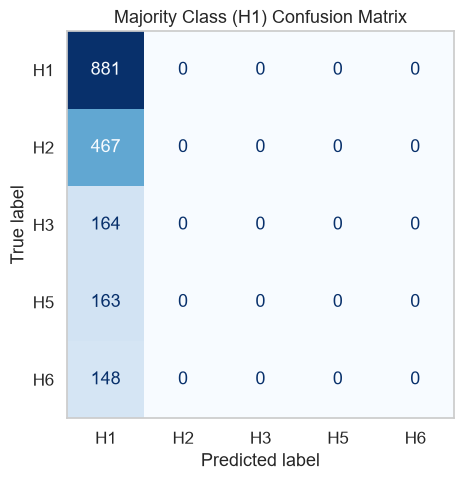

In [16]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, colorbar=False)
plt.title(f"Majority Class ({majority_class}) Confusion Matrix")
plt.grid(False)
plt.tight_layout()
plt.show()
